# UPMaBoSS: population dynamics of the cell fate model

This notebook reproduces the analyses of the UPMaBoSS article
([Stoll et al., 2022](https://doi.org/10.3389/fmolb.2022.800152)) on the cell fate model of the
[MaBoSS website](https://maboss.curie.fr).

UPMaBoSS simulates the dynamics of a population of cells, taking into account both their intracellular and
intercellular regulations. The logical model of an individual cell is a MaBoSS model. At regular intervals,
the simulation is stopped, and the population is updated according to the nodes representing cell death and
cell division, and to the nodes accounting for signals coming from other cells. The simulation then continues
with the updated conditions, until the maximum time is reached.

The model is a modified version of the cell fate model of
[Calzone et al. (2010)](https://doi.org/10.1371/journal.pcbi.1000702): it accounts for the activation of TNFα by
NFκB, and includes two output nodes, `Division` and `Death`.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/) and [SciPy](https://scipy.org/), and the files
`CellFateModel_uppmaboss.bnd`, `CellFateModel_uppmaboss.cfg` and `CellFateModel_uppmaboss.upp`, in the same
folder as this notebook. The last section (the study of all the mutants) takes about half an hour.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


## The model

Three files are needed:
* the model, `CellFateModel_uppmaboss.bnd`;
* the configuration file, `CellFateModel_uppmaboss.cfg`, with the transition rates, the simulation parameters and
  the initial conditions;
* the update file, `CellFateModel_uppmaboss.upp`, which describes the population updates.

In [2]:
bnd_file = "CellFateModel_uppmaboss.bnd"
cfg_file = "CellFateModel_uppmaboss.cfg"
upp_file = "CellFateModel_uppmaboss.upp"

model_WT = maboss.load(bnd_file, cfg_file)
print(open(upp_file).read())

death = Death;
division = Division ;
$TNF_induc u= $ProdTNF_NFkB*p[(NFkB,Death) = (1,0)];
steps = 48;
MaBoSS = MaBoSS



In the update file:
* `death` and `division` give the nodes representing cell death and cell division;
* `$TNF_induc` is updated at each step with the proportion of living cells in which NFκB is active,
  multiplied by `$ProdTNF_NFkB`: this represents the production of TNFα by the cells in which NFκB is active,
  which then acts on the other cells;
* `steps` is the number of updates. With a duration of 1 hour for each step (`max_time = 1` in the
  configuration file), the population is simulated for 48 hours.

## MaBoSS simulation of the wild type

Before running UPMaBoSS, we run a MaBoSS simulation of the wild type model over 48 hours, without taking into
account cell death and division. It shows the behaviour of a single cell, and helps choosing the duration
of each step of UPMaBoSS: it should be smaller than the first transient effect.

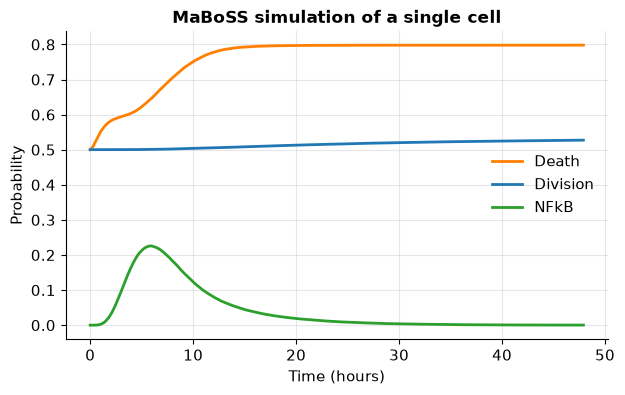

In [3]:
model_48h = maboss.copy_and_update_parameters(model_WT, {"max_time": 48})
model_48h.network.set_output(("Death", "Division", "NFkB"))
run_48h = model_48h.run()

nodes = run_48h.get_nodes_probtraj()
fig, ax = plt.subplots()
for node in ["Death", "Division", "NFkB"]:
    ax.plot(nodes.index, nodes[node], label=node)
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Probability")
ax.set_title("MaBoSS simulation of a single cell")
ax.legend()
save(fig, "upmaboss_maboss_48h")

The first transient effects occur during the first hours: steps of 1 hour capture them.

## Population dynamics, with and without the paracrine feedback

We compare two conditions, after a pulse of TNFα at t = 0: with the paracrine feedback (NFκB activates TNFα,
which acts on the other cells), and without it (`$ProdTNF_NFkB = 0`). We follow the population ratio: the size of
the population relative to the initial one.

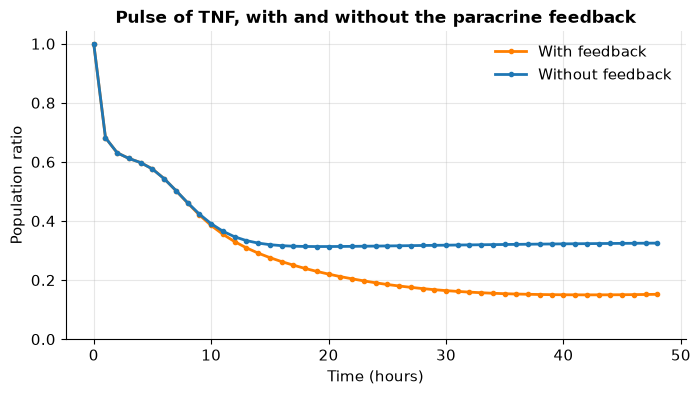

In [4]:
def population_ratios(run, name):
    """Population ratios of an UPMaBoSS run, indexed by time (in hours)."""
    ratios = run.get_population_ratios(name)
    ratios.index = ratios.index.astype(float)
    return ratios

run_WT = maboss.UpdatePopulation(model_WT, upp_file).run("WT")
ratios_WT = population_ratios(run_WT, "With feedback")

model_NoFB = maboss.copy_and_update_parameters(model_WT, {"$ProdTNF_NFkB": 0})
run_NoFB = maboss.UpdatePopulation(model_NoFB, upp_file).run("NoFB")
ratios_NoFB = population_ratios(run_NoFB, "Without feedback")

def plot_ratios(series, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, s in enumerate(series):
        ax.plot(s.index, s.values, marker="o", markersize=3, label=s.name)
    ax.set_xlabel("Time (hours)")
    ax.set_ylabel("Population ratio")
    ax.set_ylim(0, None)
    ax.set_title(title)
    ax.legend()
    return fig

fig = plot_ratios([ratios_WT, ratios_NoFB], "Pulse of TNF, with and without the paracrine feedback")
save(fig, "upmaboss_feedback")

The paracrine TNF loop leads to a significant decrease of the population size.

## Successive TNF treatments

We now simulate two successive treatments. During the first 48 hours, the cells receive a pulse of TNF at
t = 0, or no TNF. During the next 48 hours, the cells receive a constant TNF treatment (`$TNF_induc = 20`).
The second simulations start from the population at the end of the first ones (`previous_run`).

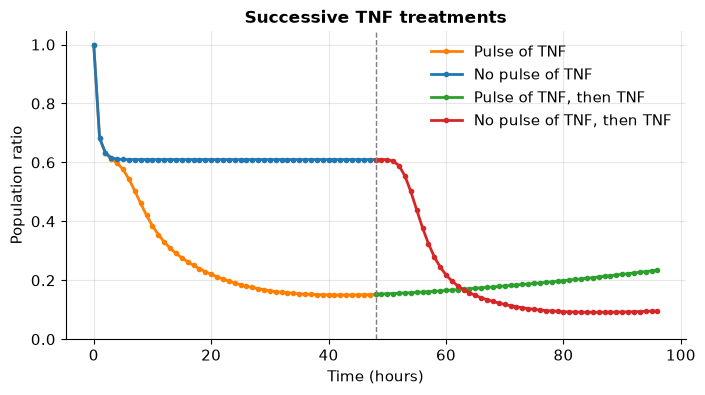

In [5]:
model_noTNF = model_WT.copy()
model_noTNF.network.set_istate("TNF", [1, 0])
run_noTNF = maboss.UpdatePopulation(model_noTNF, upp_file).run("noTNF")
ratios_noTNF = population_ratios(run_noTNF, "No pulse of TNF")

model_TNF = maboss.copy_and_update_parameters(model_WT, {"$TNF_induc": 20})
run_reTNF = maboss.UpdatePopulation(model_TNF, upp_file, previous_run=run_WT).run("reTNF")
ratios_reTNF = population_ratios(run_reTNF, "Pulse of TNF, then TNF")
run_noTNF_reTNF = maboss.UpdatePopulation(model_TNF, upp_file, previous_run=run_noTNF).run("noTNF_reTNF")
ratios_noTNF_reTNF = population_ratios(run_noTNF_reTNF, "No pulse of TNF, then TNF")

ratios_WT.name = "Pulse of TNF"
fig = plot_ratios([ratios_WT, ratios_noTNF, ratios_reTNF, ratios_noTNF_reTNF], "Successive TNF treatments")
ax = fig.axes[0]
ax.axvline(48, color="#7F7F7F", linestyle="--", linewidth=1)
save(fig, "upmaboss_treatments")

The population that received an initial pulse of TNF is resistant to the second treatment: its population
ratio does not decrease, while the population which did not receive the initial pulse is strongly reduced.

## TNF resistance of the mutants

We study the conditions of TNF resistance by simulating the deletion of each internal node of the model.
For each mutant, four protocols are simulated, combining the initial and the second treatments: no pulse of
TNF or a pulse of TNF, followed by no TNF or by TNF. We collect the population ratio at the end of the 96 hours.

*This section takes about half an hour.*

In [6]:
workdir = "TNF_sensitivity"

def tnf_effect(model, name):
    """Final population ratios of a model variant, for the four protocols."""
    model_pulse = model
    model_nopulse = model.copy()
    model_nopulse.network.set_istate("TNF", [1, 0])
    model_tnf = maboss.copy_and_update_parameters(model, {"$TNF_induc": 20})
    model_notnf = model

    results = {}
    for first, first_model in [("No pulse TNF", model_nopulse), ("Pulse TNF", model_pulse)]:
        first_run = maboss.UpdatePopulation(first_model, upp_file).run(
            os.path.join(workdir, name, first.replace(" ", "_")))
        for second, second_model in [("no TNF", model_notnf), ("TNF", model_tnf)]:
            second_run = maboss.UpdatePopulation(second_model, upp_file, previous_run=first_run).run(
                os.path.join(workdir, name, f"{first}_{second}".replace(" ", "_")))
            results[f"{first}, {second}"] = second_run.get_population_ratios().iloc[-1]
    return pd.Series(results, name=name)

excluded = {"NonACD", "Apoptosis", "Survival", "Division", "Death", "TNF", "apoptosome"}
mutants = sorted(n for n in model_WT.network.names if n not in excluded)

ratios = [tnf_effect(model_WT, "WT")]
for node in mutants:
    ratios.append(tnf_effect(maboss.copy_and_mutate(model_WT, [node], "OFF"), node))
ratios = pd.DataFrame(ratios)

Final population ratios for the wild type and each mutant:

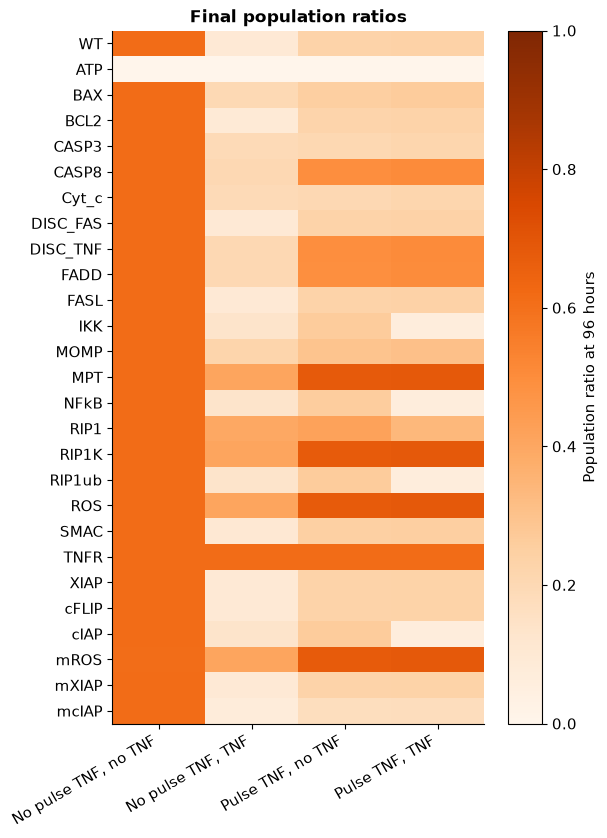

In [7]:
fig, ax = plt.subplots(figsize=(6, 9))
image = ax.imshow(ratios.values, cmap="Oranges", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(ratios.columns)), ratios.columns, rotation=30, ha="right")
ax.set_yticks(range(len(ratios.index)), ratios.index)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Population ratio at 96 hours")
ax.set_title("Final population ratios")
save(fig, "upmaboss_mutants_ratios")

To summarize these results, we compute the relative effect of the TNF treatment: the population ratio with
the second TNF treatment, divided by the population ratio without it, for the cells that received a pulse of TNF
or not. The treatment has an effect when this relative change is below 1 (in blue). The mutants are ordered
by hierarchical clustering.

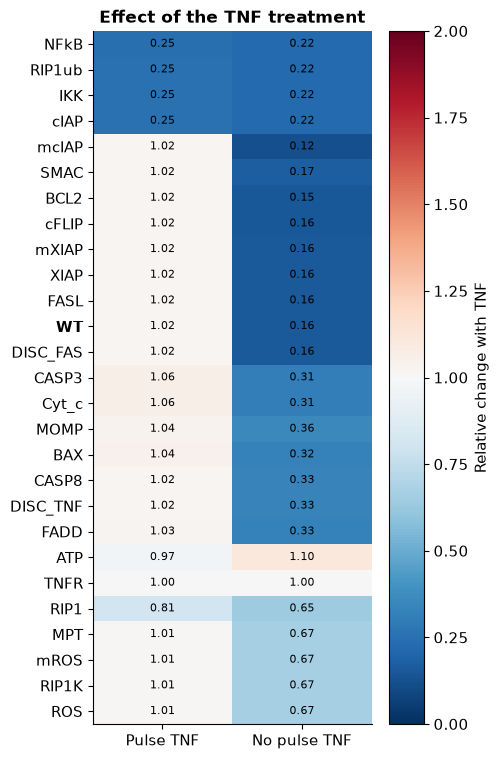

In [8]:
from scipy.cluster.hierarchy import leaves_list, linkage

relative = pd.DataFrame({
    "Pulse TNF": ratios["Pulse TNF, TNF"] / ratios["Pulse TNF, no TNF"],
    "No pulse TNF": ratios["No pulse TNF, TNF"] / ratios["No pulse TNF, no TNF"],
})
relative = relative.iloc[leaves_list(linkage(relative.values, method="average"))]

fig, ax = plt.subplots(figsize=(4.5, 9))
image = ax.imshow(relative.values, cmap="RdBu_r", norm=mpl.colors.TwoSlopeNorm(vcenter=1, vmin=0, vmax=2),
                  aspect="auto")
for (i, j), value in np.ndenumerate(relative.values):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(relative.columns)), relative.columns)
ax.set_yticks(range(len(relative.index)), relative.index)
ax.get_yticklabels()[list(relative.index).index("WT")].set_fontweight("bold")
ax.grid(False)
fig.colorbar(image, ax=ax, label="Relative change with TNF")
ax.set_title("Effect of the TNF treatment")
save(fig, "upmaboss_mutants_effect")

The relative change is the population ratio with the constant TNF treatment divided by the one without TNF.

* For a first group of mutants (the deletions of IKK, NFκB, cIAP or RIP1ub), there is no resistance: the TNF
  treatment reduces the population size, whether the cells received a pulse of TNF or not.
* For a second group, including the wild type (and for instance the BCL2 or XIAP deletions), the TNF treatment
  reduces the population size, but this effect disappears when the cells received a pulse of TNF: this indicates
  a resistance.
* Finally, the deletion of TNFR leads to insensitive cells, as expected (as does the deletion of ATP, but because
  all the cells die, whatever the treatment).